# SE match posterior: linear model 2 chgpt

Paper figures 4. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    from WERM.config import unif_prior_to_η_φ
    from WERM.config import η_to_ψ
    from WERM.signal_priors import GaussianSignal
    import WERM.model as model
    import WERM.general_fixed_point_eqns as fp
    import WERM.M_est_fixed_point_eqns as M_est
    import WERM.gof
    import WERM.performance_measures
    import WERM.general_fixed_point_eqns as fp
    import WERM.marginals
    import WERM.config
    import numpy as np
    import jax.numpy as jnp
    import jax
    import numpy.random as nprandom
    import matplotlib.pyplot as plt
    import scipy
    from sklearn import linear_model
    from functools import partial
    from tqdm import tqdm
    import time
    tqdm = partial(tqdm, position=0, leave=True)
    import jax.random
    import importlib
    import WERM.estimators
    importlib.reload(WERM.estimators)
    importlib.reload(fp)
    import WERM.posterior
    importlib.reload(WERM.posterior)
    random_seed = 42
    np.random.seed(random_seed)
    MASTER_KEY = jax.random.PRNGKey(random_seed)
    p = 1000
    L = 3
    noise_std = 1.0
    M = lambda u, v: jnp.power(u - v, 2)
    num_trials = 40
    fractional_chgpt_locations = np.array([0.3, 0.6])
    δ = 4.0
    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n * fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int)
    Δ = lambda n: int(n / 5)
    Delta_n = int(Δ(n))
    L_is_upper_bound = False
    if Delta_n == 1:
        if L_is_upper_bound:
            pi_i_l = lambda L, l, i: 1 / (L - l + 1) * np.sum([scipy.special.comb(k - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (k - l) for k in range(l, L + 1)])
        else:
            pi_i_l = lambda L, l, i: scipy.special.comb(L - 1, l - 1, exact=False) * (i / n) ** (l - 1) * (1 - i / n) ** (L - l)
        pi = np.zeros((L, n))
        for l in range(L):
            for i in range(n):
                pi[l, i] = pi_i_l(L, l + 1, i + 1)
    else:
        n_small = 100
        Delta_n_small = int(Delta_n * n_small / n)
        if L_is_upper_bound:
            p_l = 1 / L * np.ones(L)
            Lmin = 1
            Lmax = L
        else:
            p_l = None
            Lmin = L
            Lmax = L
        pi = WERM.config.extrapolated_marginals(Lmin, Lmax, Delta_n_small, n_small=n_small, n_large=n, p_l=p_l, verbose=False)
    π = pi
    if L == 1:
        π = np.ones((1, n))
    plt.plot(π.T)
    r_s = 0.1
    AR1 = np.fromfunction(lambda i, j: r_s ** np.abs(i - j), (p, p))
    Sigma = AR1
    Sigma_chol = np.linalg.cholesky(Sigma + 1e-12 * np.eye(p))
    κ = 1.0
    B̃_cov = κ ** 2 * δ * np.eye(L)
    B̃_cov[0, 1] = 0.1 * κ ** 2 * δ
    B̃_cov[1, 0] = 0.1 * κ ** 2 * δ
    signal_prior = GaussianSignal(B̃_cov)
    B̃ = signal_prior.sample(p)
    ρ = 1 / δ * (1 / p) * (B̃.T @ Sigma_chol @ Sigma_chol.T @ B̃)
    key = jax.random.PRNGKey(0)
    model_q = model.q_linear_model
    ε = np.random.randn(n) * noise_std
    all_fp_solns = fp.compute_all_fixed_points_naive(n, L, Δ(n), M, ρ, δ, π, ε, model_q, coarse_grain_factor=100000, master_key=MASTER_KEY)
    (b, nu, kappa, success_status) = fp.compute_single_fixed_point(true_chgpt_locations(n), M, ρ, δ, π, ε, n, model_q, MASTER_KEY)
    cp_arr = np.array([lis[0] for lis in all_fp_solns])
    nu_arr = np.array([lis[2] for lis in all_fp_solns]).reshape((-1, L, L))
    kappa_arr = np.array([lis[3] for lis in all_fp_solns]).reshape((-1, L, L))
    p_η_arr = np.ones((len(cp_arr),)) / len(cp_arr)
    post_samples = np.zeros((num_trials, len(cp_arr)))
    theory_post_samples = np.zeros((num_trials, len(cp_arr)))
    for trial_num in tqdm(range(num_trials)):
        X = np.random.normal(0, np.sqrt(1 / n), (n, p))
        X = X @ Sigma_chol.T
        Θ = X @ B̃
        y_fn = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0), out_axes=0)
        y = y_fn(Θ, C_true, ε)
        (cp, gof, B̂) = WERM.estimators.weighted_erm(X, y, M, L, Δ(n), 0.0, L_is_upper_bound=L_is_upper_bound, brute_force=False, return_gof=True, return_B_hat=True)
        Theta_hat = X @ B̂
        (Theta_deb, b_hat) = WERM.posterior.compute_debiased_theta(Theta_hat, y, M, π, δ, output_b_hat=True, history_size=5, ridge=1e-08, maxiter=1000, learning_rate=0.3, use_iterate_averaging=True)
        σ = noise_std
        posterior = WERM.posterior.exact_posterior_gaussian(cp_arr.astype(float), p_η_arr, Theta_deb, y, ρ, σ, nu_arr, kappa_arr)
        post_samples[trial_num, :] = posterior
        Z = np.random.multivariate_normal(np.zeros(L), ρ, size=n)
        G_Theta = np.random.multivariate_normal(np.zeros(L), kappa, size=n)
        V = Z @ nu + G_Theta
        ε_theory = np.random.randn(n) * noise_std
        y_bar = y_fn(Z, C_true, ε_theory)
        theory_post = WERM.posterior.exact_posterior_gaussian(cp_arr, p_η_arr, V, y_bar, ρ, σ, nu_arr, kappa_arr)
        theory_post_samples[trial_num, :] = theory_post


In [3]:
if RUN_EXPERIMENTS:
    import pickle
    experiment_results = {'cp_arr': cp_arr, 'post_samples': post_samples, 'theory_post_samples': theory_post_samples, 'fractional_chgpt_locations': fractional_chgpt_locations, 'n': n, 'p': p, 'L': L, 'noise_std': noise_std, 'true_chgpt_locations': true_chgpt_locations(n) if fractional_chgpt_locations.size != 0 else None, 'B̃': B̃, 'Sigma': Sigma, 'Sigma_chol': Sigma_chol, 'κ': κ, 'B̃_cov': B̃_cov, 'π': π, 'delta': δ, 'nu_arr': nu_arr, 'kappa_arr': kappa_arr}
    with open('results/Ls_experiment_1_results_newvarepsilon.pkl', 'wb') as f:
        pickle.dump(experiment_results, f)


## Load data and view it

In [4]:
if REGENERATE_FIGURES:
    import pickle
    import numpy as np
    import matplotlib
    matplotlib.use('pgf')
    import matplotlib.pyplot as plt
    from scipy.ndimage import gaussian_filter
    from scipy.interpolate import griddata
    plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 16, 'axes.titlesize': 16, 'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 13, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.08})
    x_y_label_fontsize = 22

    def _prepare_smoothed_grid(cp_grid, probabilities, sigma=1.0, grid_resolution=180, method='cubic'):
        x = cp_grid[:, 0]
        y = cp_grid[:, 1]
        xi = np.linspace(x.min(), x.max(), grid_resolution)
        yi = np.linspace(y.min(), y.max(), grid_resolution)
        (Xi, Yi) = np.meshgrid(xi, yi)
        Zi = griddata((x, y), probabilities, (Xi, Yi), method=method, fill_value=0.0)
        Zi = np.nan_to_num(Zi, nan=0.0, posinf=0.0, neginf=0.0)
        Zi = gaussian_filter(Zi, sigma=sigma)
        total = Zi.sum()
        if total > 0:
            Zi = Zi / total
        return (Xi, Yi, Zi, (x.min(), x.max()), (y.min(), y.max()))

    def plot_posterior_comparison_compact(cp_grid_empirical, probabilities_empirical, cp_grid_theory, probabilities_theory, sigma=1.0, grid_resolution=180, true_changepoints=None, titles=('\\textbf{Empirical}', '\\textbf{Theory}'), xlabel='Change point 1', ylabel='Change point 2', cmap='viridis', figsize=(8.2, 3.8), contour_levels=6, add_contours=True, contour_alpha=0.22, save_path_pdf=None, save_path_pgf=None):
        posteriors = [(cp_grid_empirical, probabilities_empirical, titles[0]), (cp_grid_theory, probabilities_theory, titles[1])]
        prepared = []
        (vmin, vmax) = (0.0, 0.0)
        for (cp_grid, probs, title) in posteriors:
            (Xi, Yi, Zi, xlim, ylim) = _prepare_smoothed_grid(cp_grid, probs, sigma=sigma, grid_resolution=grid_resolution)
            Zi = np.clip(Zi, 0, None)
            prepared.append((Xi, Yi, Zi, xlim, ylim, title))
            vmax = max(vmax, Zi.max())
        cbar_ticks = np.linspace(0, vmax - 5e-05, 4)
        (fig, axes) = plt.subplots(1, 2, figsize=figsize, sharex=False, sharey=True, constrained_layout=True, gridspec_kw={'wspace': 0.04})
        images = []
        for (ax, (Xi, Yi, Zi, xlim, ylim, title)) in zip(axes, prepared):
            im = ax.pcolormesh(Xi, Yi, Zi, cmap=cmap, shading='auto', vmin=vmin, vmax=vmax)
            im.set_rasterized(True)
            images.append(im)
            if add_contours:
                positive = Zi[Zi > 0]
                if positive.size > 0:
                    levels = np.quantile(positive, np.linspace(0.55, 0.95, contour_levels))
                    levels = np.unique(levels)
                    if len(levels) > 1:
                        ax.contour(Xi, Yi, Zi, levels=levels, colors='black', linewidths=0.8, alpha=contour_alpha)
            if true_changepoints is not None:
                ax.scatter(true_changepoints[0], true_changepoints[1], marker='*', s=180, c='black', edgecolors='white', linewidths=1.2, zorder=10, label='\\textbf{True change points}')
            ax.set_xlim(*xlim)
            ax.set_ylim(*ylim)
            ax.set_xlabel(xlabel, fontsize=x_y_label_fontsize)
            if title is not None:
                ax.set_title(title, pad=8)
            ax.tick_params(axis='both', which='major', width=1.5, length=5)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
        axes[0].set_ylabel(ylabel, fontsize=x_y_label_fontsize)
        if true_changepoints is not None:
            axes[0].legend(loc='upper right', frameon=True, edgecolor='black', framealpha=0.95, handlelength=1.2, borderpad=0.3, fontsize=16)
        cbar = fig.colorbar(images[0], ax=axes, location='right', shrink=0.92, pad=0.02, fraction=0.08, ticks=cbar_ticks)
        cbar.ax.tick_params(width=1.2, length=4)
        cbar.outline.set_linewidth(1.2)
        if save_path_pdf:
            fig.savefig(save_path_pdf, dpi=300)
        if save_path_pgf:
            fig.savefig(save_path_pgf, dpi=300)
        return (fig, axes)
    with open('results/Ls_experiment_1_results_newvarepsilon.pkl', 'rb') as f:
        loaded_results = pickle.load(f)
    cp_arr_loaded = loaded_results['cp_arr']
    post_samples_loaded = loaded_results['post_samples']
    theory_post_samples_loaded = loaded_results['theory_post_samples']
    fractional_chgpt_locations_loaded = loaded_results['fractional_chgpt_locations']
    n_loaded = loaded_results['n']
    true_cp = (fractional_chgpt_locations_loaded[0] * n_loaded, fractional_chgpt_locations_loaded[1] * n_loaded) if len(fractional_chgpt_locations_loaded) >= 2 else None
    (fig, axes) = plot_posterior_comparison_compact(cp_grid_empirical=cp_arr_loaded, probabilities_empirical=post_samples_loaded.mean(axis=0), cp_grid_theory=cp_arr_loaded, probabilities_theory=theory_post_samples_loaded.mean(axis=0), sigma=1.0, grid_resolution=180, true_changepoints=true_cp, titles=(None, None), xlabel='Change point 1', ylabel='Change point 2', cmap='viridis', figsize=(10, 3.5), contour_levels=6, add_contours=True, save_path_pdf='figures/SE_match_posterior_new_shorter_Ls_comparison_newvarepsilon.pdf', save_path_pgf='figures/SE_match_posterior_new_shorter_Ls_comparison_newvarepsilon.pgf')
    plt.close("all")


## Figure 4

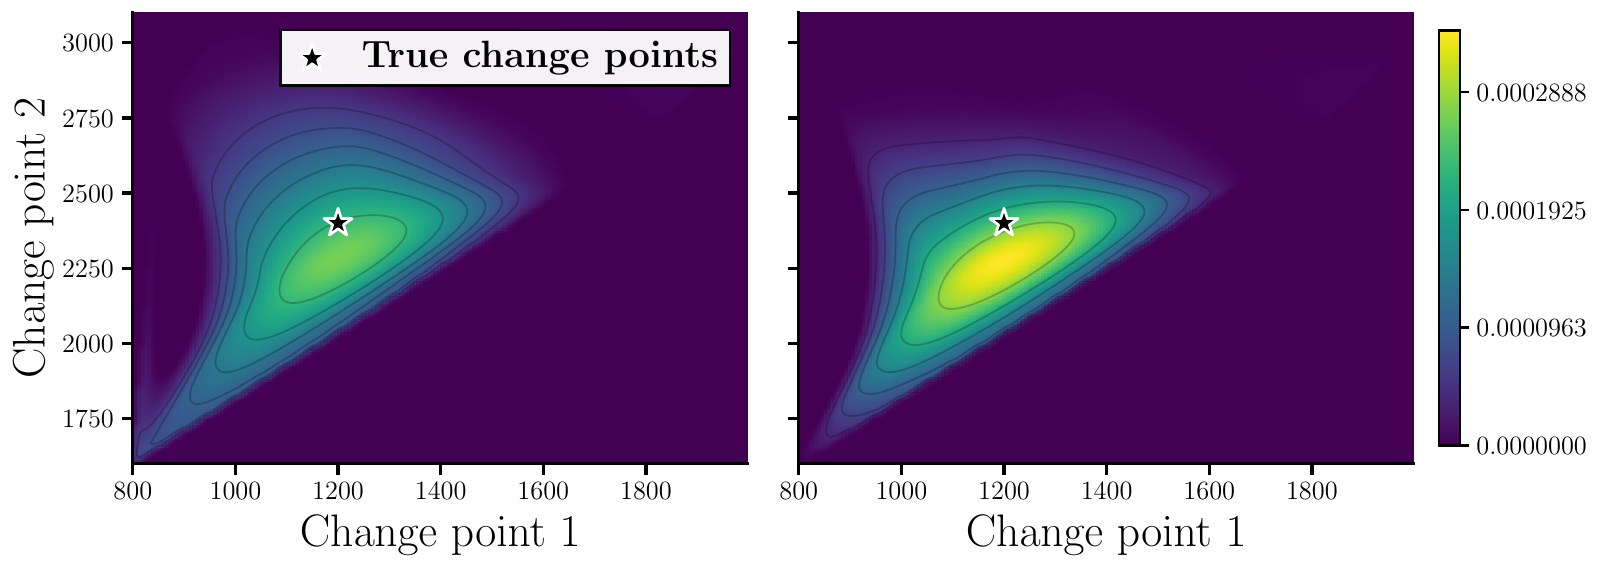

In [5]:
panels = ['figures/SE_match_posterior_new_shorter_Ls_comparison_newvarepsilon.pdf'] if REGENERATE_FIGURES else ['figures/figure_04/panel_01.pdf']
show_panels(panels)
